# Projet de Recherche Opérationnelle — SAHEL Ameublement

**Université Amadou Makhtar Mbow (UFR-STA) — Licence 3 Informatique — 2025-2026**
**Enseignant responsable : Dr Cheikh GUEYE**

Ce notebook résout le problème de production de la coopérative « SAHEL Ameublement » avec deux outils Python : **PuLP** (modélisation algébrique) et **SciPy** (`linprog`, modélisation matricielle). Il complète la résolution sous Excel (Solveur) livrée dans le classeur `projet RO EXCEL.xlsx`.

## 0. Installation et importations

**Pourquoi `pulp<4` ?** La version 4 de PuLP a changé son interface : `LpVariable("x", lowBound=0)`, utilisé dans l'énoncé du projet, y provoque une erreur (`unexpected keyword argument 'lowBound'`). La version 3.x, testée ici (3.3.2), conserve la syntaxe de l'énoncé.

Bibliothèques utilisées :
- `pulp` : définition du modèle sous forme d'expressions algébriques, résolution par le solveur CBC ;
- `scipy.optimize.linprog` : résolution à partir de tableaux (matrices et vecteurs), avec le solveur HiGHS ;
- `numpy`, `pandas` : manipulation et affichage des résultats ;
- `matplotlib` : graphiques de sensibilité.

À exécuter une fois dans un terminal (ou dans une cellule précédée de `%`) avant de lancer le notebook :

```
pip install "pulp<4" scipy numpy pandas matplotlib
```

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pulp import LpProblem, LpMaximize, LpMinimize, LpVariable, LpStatus, lpSum, value, PULP_CBC_CMD
from scipy.optimize import linprog

## 1. Rappel du modèle mathématique

**Variables de décision** (quantités hebdomadaires) : $x_1$ tables, $x_2$ chaises, $x_3$ armoires.

$$\max Z = 15\,000\,x_1 + 4\,000\,x_2 + 22\,000\,x_3$$

sous les contraintes

$$\begin{aligned}
8x_1 + 2x_2 + 12x_3 &\le 900 &&\text{(bois)}\\
4x_1 + 1{,}5x_2 + 6x_3 &\le 400 &&\text{(main-d'œuvre)}\\
2x_1 + x_2 + 3x_3 &\le 220 &&\text{(machine)}\\
x_2 &\le 60 &&\text{(marché)}\\
x_3 &\ge 10 &&\text{(contrat)}\\
x_1,\,x_2,\,x_3 &\ge 0
\end{aligned}$$

**Choix de modélisation :** les contraintes (marché) et (contrat) ne portent que sur **une seule variable**. Les deux outils savent les traiter comme de simples **bornes de variables** ($0 \le x_2 \le 60$ et $x_3 \ge 10$) plutôt que comme des lignes de la matrice des contraintes. C'est équivalent mathématiquement, et plus efficace pour le solveur. Seules les trois contraintes de ressources restent donc dans la matrice.

## 2. Résolution avec PuLP (approche algébrique)

**Ce que fait chaque bloc :**
1. `LpProblem(..., LpMaximize)` crée le problème et indique le sens d'optimisation. PuLP gère nativement la maximisation.
2. `LpVariable` déclare chaque variable avec ses bornes (`lowBound`, `upBound`) : c'est ici qu'on encode les contraintes (marché) et (contrat).
3. `prob += expression, "nom"` ajoute au problème, selon la forme de l'expression : la **fonction objectif** (une expression sans comparaison) ou une **contrainte** (une expression avec `<=`). Le nom permet de retrouver la contrainte ensuite.
4. `prob.solve(PULP_CBC_CMD(msg=0))` lance le solveur CBC en mode silencieux.
5. `LpStatus` traduit le code de statut en texte (`Optimal`, `Infeasible`...), qu'il faut toujours vérifier avant de lire les valeurs.

In [2]:
prob = LpProblem("Production_SAHEL", LpMaximize)

x1 = LpVariable("Tables", lowBound=0)
x2 = LpVariable("Chaises", lowBound=0, upBound=60)
x3 = LpVariable("Armoires", lowBound=10)

prob += 15000 * x1 + 4000 * x2 + 22000 * x3, "Marge_totale"

prob += 8 * x1 + 2 * x2 + 12 * x3 <= 900, "Bois"
prob += 4 * x1 + 1.5 * x2 + 6 * x3 <= 400, "Main_oeuvre"
prob += 2 * x1 + x2 + 3 * x3 <= 220, "Machine"

prob.solve(PULP_CBC_CMD(msg=0))

print("Statut :", LpStatus[prob.status])
for v in (x1, x2, x3):
    print(v.name, "=", v.varValue)
print("Marge optimale =", value(prob.objective))

Statut : Optimal
Tables = 85.0
Chaises = 0.0
Armoires = 10.0
Marge optimale = 1495000.0


**Lecture du résultat :** le statut est `Optimal` et le plan de production est $x_1 = 85$ tables, $x_2 = 0$ chaise, $x_3 = 10$ armoires pour une marge de **1 495 000 FCFA** par semaine. Les armoires sont au minimum imposé par le contrat.

### Prix duaux et écarts

- Le **prix dual** (`constraint.pi`) d'une contrainte est le gain de marge obtenu si on augmente d'une unité son second membre.
- L'**écart** (`constraint.slack`) est la quantité de ressource **non utilisée**. Un écart nul signifie que la contrainte est **saturée** (elle bloque l'optimum). Un écart positif signifie qu'il reste de la ressource, donc que son prix dual est nul.
- Le **coût réduit** (`variable.dj`) mesure ce que coûterait, ou rapporterait, une variation d'une unité d'une variable située sur sa borne.

La ligne `round(..., 6) + 0.0` supprime les « -0.0 » parasites dus aux arrondis du solveur.

In [3]:
lignes = []
for nom, c in prob.constraints.items():
    lignes.append({
        "Contrainte": nom,
        "Prix dual (pi)": round(c.pi, 6) + 0.0,
        "Ecart (slack)": round(c.slack, 6) + 0.0,
        "Statut": "saturee" if abs(c.slack) < 1e-9 else "non saturee",
    })
pd.DataFrame(lignes)

,Contrainte,Prix dual (pi),Ecart (slack),Statut
0,Bois,0.0,100.0,non saturee
1,Main_oeuvre,3750.0,0.0,saturee
2,Machine,0.0,20.0,non saturee


In [4]:
pd.DataFrame([
    {"Variable": v.name, "Valeur": v.varValue, "Cout reduit (dj)": round(v.dj, 6) + 0.0}
    for v in (x1, x2, x3)
])

,Variable,Valeur,Cout reduit (dj)
0,Tables,85.0,0.0
1,Chaises,0.0,-1625.0
2,Armoires,10.0,-500.0


**Interprétation :**
- **Main-d'œuvre** : écart 0 et prix dual 3 750. C'est la seule ressource physique saturée : chaque heure supplémentaire rapporte 3 750 FCFA (15 000 FCFA de marge d'une table, divisés par les 4 heures qu'elle consomme).
- **Bois** (écart 100) et **machine** (écart 20) : non saturés, prix duaux nuls. Acheter plus de bois ou de machine ne rapporterait rien.
- **Chaises** : coût réduit −1 625. Fabriquer une chaise ferait perdre 1 625 FCFA, car elle immobilise 1,5 h de main-d'œuvre qui vaut 3 750 FCFA/h (soit 5 625 FCFA) pour une marge de seulement 4 000 FCFA.
- **Armoires** : coût réduit −500, identique à celui du rapport Excel. Une armoire consomme 6 h de main-d'œuvre (22 500 FCFA au prix dual) pour 22 000 FCFA de marge : chaque armoire fabriquée au-delà de ce qui est strictement nécessaire fait perdre 500 FCFA. Le contrat impose le minimum de 10 ; la variable reste donc à sa borne inférieure.

## 3. Résolution avec SciPy `linprog` (approche matricielle)

**Pourquoi transformer le problème ?** `linprog` ne sait que **minimiser** et attend le problème sous la forme

$$\min\; c^{\top}x \quad\text{sous}\quad A_{ub}\,x \le b_{ub},\quad \text{bornes sur } x.$$

Maximiser $Z$ revient à minimiser $-Z$ : on prend donc `c = -[15000, 4000, 22000]` et on rétablit le signe à la fin (`-res.fun`).

Chaque ligne de `A_ub` correspond à une ressource et chaque colonne à une variable ($x_1, x_2, x_3$). Les bornes sont données séparément : `None` signifie « pas de limite ». La méthode `"highs"` appelle le solveur HiGHS, le plus performant disponible dans SciPy.

In [5]:
c = [-15000, -4000, -22000]

A_ub = [
    [8, 2, 12],
    [4, 1.5, 6],
    [2, 1, 3],
]
b_ub = [900, 400, 220]

bounds = [(0, None), (0, 60), (10, None)]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")

print("Succes :", res.success)
print("Solution optimale :", res.x)
print("Marge optimale :", -res.fun)

Succes : True
Solution optimale : [85.  0. 10.]
Marge optimale : 1495000.0


SciPy fournit aussi l'équivalent des écarts et des prix duaux :
- `res.slack` : écart de chaque contrainte `A_ub x <= b_ub` ;
- `res.ineqlin.marginals` : sensibilité de la fonction **minimisée** ($-Z$) au second membre. Comme on a minimisé $-Z$, il faut **changer le signe** pour retrouver le prix dual de la marge.

In [6]:
pd.DataFrame({
    "Contrainte": ["Bois", "Main_oeuvre", "Machine"],
    "Prix dual": -res.ineqlin.marginals + 0.0,
    "Ecart (slack)": res.slack,
})

,Contrainte,Prix dual,Ecart (slack)
0,Bois,0.0,100.0
1,Main_oeuvre,3750.0,0.0
2,Machine,0.0,20.0


## 4. Vérification : Excel, PuLP et SciPy donnent-ils la même solution ?

Les valeurs « Excel » sont celles lues dans le rapport des réponses du Solveur (cellules `E3:G3` et `H4`). La comparaison utilise `np.allclose`, qui accepte de très petits écarts d'arrondi (Excel affiche par exemple 9,999999999999993 au lieu de 10).

In [7]:
excel = np.array([85.0, 0.0, 10.0])
pulp_sol = np.array([x1.varValue, x2.varValue, x3.varValue])
scipy_sol = res.x

comparaison = pd.DataFrame({
    "Excel Solveur": list(excel) + [1495000.0],
    "PuLP (CBC)": list(pulp_sol) + [value(prob.objective)],
    "SciPy (HiGHS)": list(scipy_sol) + [-res.fun],
}, index=["Tables (x1)", "Chaises (x2)", "Armoires (x3)", "Marge Z* (FCFA)"])

print(comparaison.round(4))
print()
print("PuLP = Excel :", np.allclose(pulp_sol, excel))
print("SciPy = Excel :", np.allclose(scipy_sol, excel))
print("PuLP = SciPy :", np.allclose(pulp_sol, scipy_sol))

                 Excel Solveur  PuLP (CBC)  SciPy (HiGHS)
Tables (x1)               85.0        85.0           85.0
Chaises (x2)               0.0         0.0            0.0
Armoires (x3)             10.0        10.0           10.0
Marge Z* (FCFA)      1495000.0   1495000.0      1495000.0

PuLP = Excel : True
SciPy = Excel : True
PuLP = SciPy : True


Les trois outils retrouvent la **même solution** ($85;\;0;\;10$) et la même marge. C'est attendu : le problème est un programme linéaire à optimum unique, et les trois solveurs sont des méthodes exactes (simplexe pour Excel et CBC, simplexe dual pour HiGHS).

## 5. Analyse de sensibilité

La fonction ci-dessous résout à nouveau le problème avec `linprog` pour des disponibilités modifiées. Elle sert à **vérifier numériquement** les plages de validité données par le rapport de sensibilité d'Excel, plutôt que de les prendre pour acquises.

**Bois.** Excel indique : prix dual nul, diminution admissible de 100 m. La disponibilité peut donc descendre jusqu'à **800 m** (900 − 100) sans changer la base optimale. En dessous de 800 m, le bois devient saturé et la marge baisse. Au-dessus de 900 m, il ne se passe rien.

In [8]:
def marge(bois=900, mo=400, machine=220, chaises_max=60, armoires_min=10):
    r = linprog(
        c,
        A_ub=A_ub,
        b_ub=[bois, mo, machine],
        bounds=[(0, None), (0, chaises_max), (armoires_min, None)],
        method="highs",
    )
    return -r.fun if r.success else np.nan

pd.DataFrame({
    "Bois disponible (m)": [700, 750, 800, 850, 900, 1000, 1200],
    "Marge Z* (FCFA)": [marge(bois=b) for b in [700, 750, 800, 850, 900, 1000, 1200]],
})

,Bois disponible (m),Marge Z* (FCFA)
0,700,1322500.0
1,750,1413750.0
2,800,1495000.0
3,850,1495000.0
4,900,1495000.0
5,1000,1495000.0
6,1200,1495000.0


**Lecture :** la marge reste à 1 495 000 FCFA pour tout bois supérieur ou égal à 800 m, et chute dès que l'on passe sous 800 m. La plage annoncée par Excel (800 m à l'infini) est donc confirmée.

**Main-d'œuvre.** Excel indique un prix dual de 3 750 FCFA/h valable de 60 h (400 − 340) à 440 h (400 + 40). Au-delà de 440 h, c'est la machine qui devient saturée (220 h) et le prix dual de la main-d'œuvre tombe à 0. Vérification : la pente de la marge doit valoir 3 750 FCFA/h sur [60 ; 440] puis s'annuler.

In [9]:
mo_valeurs = [60, 100, 200, 300, 400, 440, 480, 600]
z_mo = [marge(mo=m) for m in mo_valeurs]
pentes = [None] + [
    (z_mo[i] - z_mo[i - 1]) / (mo_valeurs[i] - mo_valeurs[i - 1])
    for i in range(1, len(mo_valeurs))
]
pd.DataFrame({
    "Main-d'oeuvre (h)": mo_valeurs,
    "Marge Z* (FCFA)": z_mo,
    "Pente (FCFA/h)": pentes,
})

,Main-d'oeuvre (h),Marge Z* (FCFA),Pente (FCFA/h)
0,60,220000.0,NaN
1,100,370000.0,3750.0
2,200,745000.0,3750.0
3,300,1120000.0,3750.0
4,400,1495000.0,3750.0
5,440,1645000.0,3750.0
6,480,1645000.0,0.0
7,600,1645000.0,0.0


**Lecture :** la pente est de 3 750 FCFA/h jusqu'à 440 h, puis elle s'annule. Les bornes 60 h et 440 h du rapport Excel sont donc exactes. Le graphique ci-dessous visualise les deux courbes.

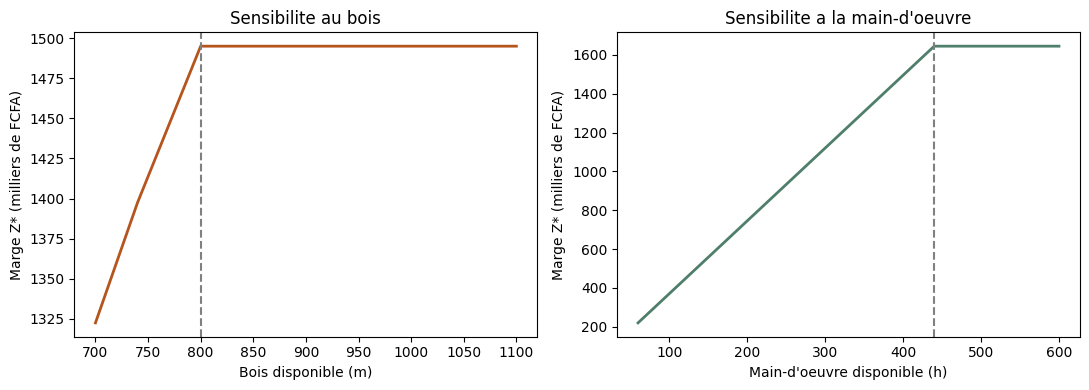

In [10]:
bois_grille = np.linspace(700, 1100, 81)
mo_grille = np.linspace(60, 600, 109)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(bois_grille, [marge(bois=b) / 1000 for b in bois_grille], color="#B5541C", linewidth=2)
axes[0].axvline(800, color="grey", linestyle="--")
axes[0].set_xlabel("Bois disponible (m)")
axes[0].set_ylabel("Marge Z* (milliers de FCFA)")
axes[0].set_title("Sensibilite au bois")

axes[1].plot(mo_grille, [marge(mo=m) / 1000 for m in mo_grille], color="#4F7F6B", linewidth=2)
axes[1].axvline(440, color="grey", linestyle="--")
axes[1].set_xlabel("Main-d'oeuvre disponible (h)")
axes[1].set_ylabel("Marge Z* (milliers de FCFA)")
axes[1].set_title("Sensibilite a la main-d'oeuvre")

plt.tight_layout()
plt.show()

## 6. Comparaison des temps d'exécution

On mesure le temps moyen d'une résolution complète (construction du modèle, résolution, lecture du résultat) sur 20 répétitions. Pour un problème aussi petit, **les différences ne sont pas significatives pour l'utilisateur**. Elles illustrent surtout l'architecture des outils : PuLP écrit un fichier et lance le programme externe CBC à chaque résolution, alors que `linprog` appelle HiGHS directement en mémoire.

In [11]:
def resoudre_pulp():
    p = LpProblem("P", LpMaximize)
    a = LpVariable("T", lowBound=0)
    b = LpVariable("C", lowBound=0, upBound=60)
    d = LpVariable("A", lowBound=10)
    p += 15000 * a + 4000 * b + 22000 * d
    p += 8 * a + 2 * b + 12 * d <= 900
    p += 4 * a + 1.5 * b + 6 * d <= 400
    p += 2 * a + b + 3 * d <= 220
    p.solve(PULP_CBC_CMD(msg=0))
    return value(p.objective)

def resoudre_scipy():
    r = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
    return -r.fun

def chrono(f, n=20):
    debut = time.perf_counter()
    for _ in range(n):
        f()
    return (time.perf_counter() - debut) / n * 1000

print("PuLP (CBC)    : %.1f ms par resolution" % chrono(resoudre_pulp))
print("SciPy (HiGHS) : %.1f ms par resolution" % chrono(resoudre_scipy))

PuLP (CBC)    : 2.8 ms par resolution
SciPy (HiGHS) : 1.1 ms par resolution


## 7. Extension (bonus) : programmation linéaire en nombres entiers

Dans la vie réelle, on ne fabrique pas 85,3 tables. On impose donc que $x_1, x_2, x_3$ soient **entiers** avec `cat="Integer"` dans PuLP. CBC utilise alors un algorithme de séparation-évaluation (*branch and bound*) qui résout une suite de problèmes linéaires.

In [12]:
def resoudre_entier(mo=400, entier=True):
    cat = "Integer" if entier else "Continuous"
    p = LpProblem("Production_entiers", LpMaximize)
    a = LpVariable("Tables", lowBound=0, cat=cat)
    b = LpVariable("Chaises", lowBound=0, upBound=60, cat=cat)
    d = LpVariable("Armoires", lowBound=10, cat=cat)
    p += 15000 * a + 4000 * b + 22000 * d
    p += 8 * a + 2 * b + 12 * d <= 900
    p += 4 * a + 1.5 * b + 6 * d <= mo
    p += 2 * a + b + 3 * d <= 220
    p.solve(PULP_CBC_CMD(msg=0))
    return [a.varValue, b.varValue, d.varValue], value(p.objective)

print("Continu (relaxe) :", resoudre_entier(entier=False))
print("Entier           :", resoudre_entier(entier=True))

Continu (relaxe) : ([85.0, 0.0, 10.0], 1495000.0)
Entier           : ([85.0, 0.0, 10.0], 1495000.0)


**Lecture :** avec les données de l'énoncé, la solution continue est **déjà entière** (85 ; 0 ; 10), donc la contrainte d'intégrité n'a aucun effet : l'écart entre solution entière et relaxation continue est nul. Cela vient du fait que les consommations de la contrainte saturée (main-d'œuvre) divisent exactement les données : $(400 - 6 \times 10)/4 = 85$.

Pour montrer un cas où l'intégrité compte, on passe la main-d'œuvre à 401 h :

In [13]:
print("Continu (relaxe) :", resoudre_entier(mo=401, entier=False))
print("Entier           :", resoudre_entier(mo=401, entier=True))

Continu (relaxe) : ([85.25, 0.0, 10.0], 1498750.0)
Entier           : ([85.0, 0.0, 10.0], 1495000.0)


Avec 401 h, la relaxation continue donne $x_1 = 85{,}25$ (non réalisable en pratique) et une marge de 1 498 750 FCFA. La solution entière reste à (85 ; 0 ; 10) avec 1 495 000 FCFA : la perte due à l'intégrité est de 3 750 FCFA, soit la valeur de l'heure de main-d'œuvre inutilisée. La solution continue constitue toujours une **borne supérieure** de la solution entière.

Le second bonus, le problème de transport, est traité à la section suivante.


## 8. Extension (bonus) : problème de transport

La coopérative doit livrer sa production hebdomadaire à trois points de vente : **Niamey, Zinder et Maradi**. Il faut choisir **combien de chaque meuble envoyer à chaque point** pour que le coût total de transport soit le plus faible possible.

> **Attention : données fictives.** L'énoncé ne fournit ni les coûts de transport, ni les demandes des points de vente. Les valeurs ci-dessous sont des **hypothèses illustratives** choisies pour que le modèle soit complet et exécutable. Pour le rendu final, **remplace-les par les valeurs données par l'enseignant** : seuls les dictionnaires `cout` et `capacite` sont à modifier, le reste du code ne change pas.

**Modèle.** Soit $e_{ij}$ le nombre de meubles de type $i$ (table, chaise, armoire) envoyés au point de vente $j$.

$$\min \sum_{i}\sum_{j} c_{ij}\, e_{ij}$$

sous les contraintes

$$\sum_{j} e_{ij} = O_i \quad\text{(toute la production } O_i \text{ est expédiée)}, \qquad 0 \le e_{ij} \le D_{ij} \quad\text{(le point } j \text{ ne peut absorber que } D_{ij} \text{ unités)}$$

- **L'offre** $O_i$ est la production optimale trouvée plus haut (85 tables, 0 chaise, 10 armoires) : on relie ainsi le transport au problème de production.
- **La demande** $D_{ij}$ est la quantité maximale que chaque point peut recevoir. Elle est supérieure à l'offre totale, donc le problème est un transport **déséquilibré** : on n'est pas obligé de satisfaire toute la demande, mais on doit expédier toute l'offre.
- Les contraintes d'offre sont des **égalités** (tout est expédié) ; les contraintes de demande sont des **bornes supérieures** sur chaque variable.
- Le coût $c_{ij}$ dépend du produit (une armoire coûte plus cher à transporter qu'une chaise) et de la destination.

In [14]:
produits = ["Tables", "Chaises", "Armoires"]
points = ["Niamey", "Zinder", "Maradi"]

offre = dict(zip(produits, [x1.varValue, x2.varValue, x3.varValue]))

cout = {
    "Tables": {"Niamey": 3500, "Zinder": 4500, "Maradi": 4000},
    "Chaises": {"Niamey": 1000, "Zinder": 1400, "Maradi": 1200},
    "Armoires": {"Niamey": 5500, "Zinder": 7000, "Maradi": 6200},
}

capacite = {
    "Tables": {"Niamey": 40, "Zinder": 30, "Maradi": 35},
    "Chaises": {"Niamey": 20, "Zinder": 15, "Maradi": 25},
    "Armoires": {"Niamey": 5, "Zinder": 4, "Maradi": 6},
}

**Ce que fait le bloc suivant :**
1. `LpMinimize` : on **minimise** un coût, contrairement au problème de production où l'on maximisait une marge.
2. `LpVariable.dicts` crée en une fois les 9 variables `envoi[(produit, point)]`, toutes positives ou nulles.
3. `lpSum` construit la somme du coût total sur tous les couples (produit, point).
4. La boucle ajoute, pour chaque produit, la contrainte d'offre (égalité) et, pour chaque couple (produit, point), la borne de demande.

In [15]:
transport = LpProblem("Transport_SAHEL", LpMinimize)

envoi = LpVariable.dicts("envoi", [(i, j) for i in produits for j in points], lowBound=0)

transport += lpSum(cout[i][j] * envoi[(i, j)] for i in produits for j in points), "Cout_total"

for i in produits:
    transport += lpSum(envoi[(i, j)] for j in points) == offre[i], "Offre_" + i
    for j in points:
        transport += envoi[(i, j)] <= capacite[i][j], "Demande_" + i + "_" + j

transport.solve(PULP_CBC_CMD(msg=0))

print("Statut :", LpStatus[transport.status])
print("Cout de transport :", value(transport.objective), "FCFA")

Statut : Optimal
Cout de transport : 383500.0 FCFA


In [16]:
plan = pd.DataFrame(
    {j: [envoi[(i, j)].varValue for i in produits] for j in points},
    index=produits,
)
plan["Total expedie"] = plan.sum(axis=1)
print(plan)
print()
print("Marge de production :", value(prob.objective), "FCFA")
print("Cout de transport   :", value(transport.objective), "FCFA")
print("Marge nette apres transport :", value(prob.objective) - value(transport.objective), "FCFA")

          Niamey  Zinder  Maradi  Total expedie
Tables      40.0    10.0    35.0           85.0
Chaises      0.0     0.0     0.0            0.0
Armoires     5.0     0.0     5.0           10.0

Marge de production : 1495000.0 FCFA
Cout de transport   : 383500.0 FCFA
Marge nette apres transport : 1111500.0 FCFA


**Lecture du résultat (avec les données fictives) :**
- Chaque ligne du plan somme à la production : 85 tables et 10 armoires sont bien expédiées en totalité ; les chaises, non produites, ne sont pas transportées.
- **Niamey** est la destination la moins chère pour les trois produits : le solveur la remplit **en premier**, jusqu'à sa capacité (40 tables, 5 armoires).
- **Maradi** est la deuxième moins chère : elle reçoit ensuite 35 tables et 5 armoires.
- **Zinder**, la plus chère, ne reçoit que le reste : 10 tables et aucune armoire.
- Avec un seul point de départ (Dakar), la solution revient à **remplir les destinations par coût croissant**. Le solveur retrouve ce que donnerait un raisonnement « glouton », ce qui est une bonne vérification du modèle.

La marge nette après transport vaut la marge de production moins le coût de transport. Elle montre que le transport se déduit de la marge de 1 495 000 FCFA : il faut donc le prendre en compte dans une décision réelle. Ce calcul suppose que les marges unitaires de l'énoncé **ne contiennent pas** le transport, ce qui est une hypothèse du modèle.

## 9. Conclusion

- Les trois outils (Excel Solveur, PuLP, SciPy) convergent vers la même solution : **85 tables, 0 chaise, 10 armoires, marge de 1 495 000 FCFA par semaine**.
- La **main-d'œuvre** est la seule ressource saturée (avec le contrat, qui est une contrainte commerciale). Son prix dual de 3 750 FCFA/h, valable entre 60 h et 440 h, indique le prix maximum auquel il est rentable d'acheter des heures supplémentaires.
- Le **bois** (100 m) et la **machine** (20 h) sont en excès. La disponibilité du bois peut descendre jusqu'à 800 m sans conséquence.
- Le **problème de transport** (bonus), avec des données fictives à remplacer, répartit la production entre Niamey, Zinder et Maradi pour un coût minimal.
- **PuLP** est plus lisible (variables et équations nommées) ; **SciPy** est plus compact et direct (tableaux), mais exige de passer en minimisation et en forme matricielle.